<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · A withdrawal belongs to a peer

**After a path changes and is withdrawn, which observations remain?**
We will decode a RIB snapshot and an MRT update stream through VGI, reconstruct
state with SQL, and compare paths before and after a selected cutoff.

The tiny files are **synthetic fixtures**, generated by this repository. They are
not captured Internet traffic. Their timestamps begin at **2025-06-29 00:00:00 UTC**.
A peer's observation is not a global reachability verdict, and this example does
not detect hijacks or validate route origins.

## Choose how much of the update stream to apply

`UPDATES_THROUGH_SECOND` is an **inclusive** offset from 00:00:00 UTC: **0, 1 or 2**.
The default is **1**; the end experiment advances it to **2**. We keep the seed RIB
and full reference timeline fixed, then inspect state after the selected second.
Restart the kernel and run all after editing.

In [1]:
UPDATES_THROUGH_SECOND = 1

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p
    for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file() and (p / "fixtures").is_dir()
)
sys.path.insert(0, str(NOTEBOOK_DIR))
os.chdir(NOTEBOOK_DIR)

In [3]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.ticker import MaxNLocator
from notebook_support import finish, prose, theme

if (
    isinstance(UPDATES_THROUGH_SECOND, bool)
    or not isinstance(UPDATES_THROUGH_SECOND, int)
    or UPDATES_THROUGH_SECOND not in {0, 1, 2}
):
    raise ValueError(
        "UPDATES_THROUGH_SECOND must be 0, 1 or 2 (inclusive UTC seconds)."
    )
theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/vgi-bgp/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-bgp/notebooks/pyproject.toml.

## Connect to the MRT decoder

VGI downloads, verifies and caches the **v0.4.0** native release. No local Rust
build is needed. The locked notebook environment uses Haybarn **2.0.0rc11**.
Initial installation needs network access; all routing data comes from the
bundled fixture files.

The `inet` extension turns the worker's Arrow address structs into printable IP
prefixes and supports containment queries. The casts below preserve IPv4 and IPv6.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL inet FROM core;
LOAD inet;
ATTACH 'bgp' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-bgp@v0.4.0');
SELECT bgp.main.path_length([65001, 64500, 64500, 64512]) AS path_entries,
       bgp.main.as_path_prepends([65001, 64500, 64500, 64512]) AS adjacent_prepends;

,path_entries,adjacent_prepends
0,4,1


## Decode once and make input quality visible

We materialize each scan before further SQL or plotting. The main RIB and update
stream use **`strict => true`** so malformed input stops the reconstruction.
A separate, deliberately truncated RIB uses permissive mode to show error rows.

An error row is not a withdrawal. Silently dropping it would leave an incomplete
snapshot that could make routes appear absent. We keep the damaged input out of
all state and path calculations.

In [5]:
%%sql
CREATE OR REPLACE TABLE rib AS
SELECT timestamp AS observed_at, peer_ip::INET::VARCHAR AS peer_ip,
       peer_asn, prefix::INET::VARCHAR AS prefix, as_path, origin_asn, error
FROM bgp.main.read_rib('fixtures/rib.mrt', strict => true);
CREATE OR REPLACE TABLE updates AS
SELECT timestamp AS observed_at, peer_ip::INET::VARCHAR AS peer_ip,
       peer_asn, prefix::INET::VARCHAR AS prefix, message_type, as_path, origin_asn, error
FROM bgp.main.read_updates('fixtures/updates.mrt', strict => true);
CREATE OR REPLACE TABLE damaged AS
SELECT * FROM bgp.main.read_rib('fixtures/truncated.mrt');

,Count


In [6]:
%%sql quality <<
SELECT 'Complete RIB (used)' AS source,
       count(*) FILTER (WHERE error IS NULL) AS decoded_rows,
       count(*) FILTER (WHERE error IS NOT NULL) AS error_rows FROM rib
UNION ALL
SELECT 'Complete updates (used)', count(*) FILTER (WHERE error IS NULL), count(*) FILTER (WHERE error IS NOT NULL) FROM updates
UNION ALL
SELECT 'Truncated RIB (diagnostic only)', count(*) FILTER (WHERE error IS NULL), count(*) FILTER (WHERE error IS NOT NULL) FROM damaged;

In [7]:
quality = globals()["quality"]
display(quality)
used = quality[quality.source.str.endswith("(used)")]
assert (used.error_rows == 0).all() and (used.decoded_rows > 0).all()
broken = quality[quality.source.str.startswith("Truncated")].iloc[0]
prose(
    f"The damaged file returns **{int(broken.decoded_rows)} decoded row(s)** plus **{int(broken.error_rows)} error row(s)**. That is a partial decode, not evidence that the missing routes were withdrawn. Reconstruction uses only the two complete inputs."
)

,source,decoded_rows,error_rows
0,Complete RIB (used),3,0
1,Complete updates (used),3,0
2,Truncated RIB (diagnostic only),1,1


The damaged file returns **1 decoded row(s)** plus **1 error row(s)**. That is a partial decode, not evidence that the missing routes were withdrawn. Reconstruction uses only the two complete inputs.

## The same prefix can have several peer-specific paths

The state key is **peer IP + peer ASN + prefix** in this single synthetic
collector. The seed has two views of one IPv4 prefix and a separate IPv6 path.
AS-path length counts entries, including adjacent repeated ASNs. A prepend is an
extra adjacent occurrence, not an additional distinct transit network.

Production feeds also need collector/session identity where those can differ.
These fixtures omit session resets, ADD-PATH and AS_SET ambiguity.

In [8]:
%%sql
SELECT peer_ip, peer_asn, prefix, as_path, origin_asn,
       bgp.main.path_length(as_path) AS path_entries,
       bgp.main.as_path_prepends(as_path) AS adjacent_prepends
FROM rib ORDER BY prefix, peer_ip;

,peer_ip,peer_asn,prefix,as_path,origin_asn,path_entries,adjacent_prepends
0,2001:db8::1,65001,2001:db8:abcd::/48,"[65001, 64500, 64600]",64600,3,0
1,192.0.2.1,65001,203.0.113.0/24,"[65001, 64500, 64500, 64512]",64512,4,1
2,198.51.100.7,65002,203.0.113.0/24,"[65002, 64513, 64512]",64512,3,0


In [9]:
%%sql
SELECT observed_at AS observed_at_utc, peer_ip, peer_asn, prefix,
       message_type, as_path
FROM updates ORDER BY observed_at, peer_ip, prefix;

,observed_at_utc,peer_ip,peer_asn,prefix,message_type,as_path
0,2025-06-29 00:00:00,192.0.2.1,65001,203.0.113.0/24,announce,"[65001, 64500, 64512]"
1,2025-06-29 00:00:01,2001:db8::1,65001,2001:db8:abcd::/48,announce,"[65001, 64600]"
2,2025-06-29 00:00:02,192.0.2.1,65001,203.0.113.0/24,withdraw,<NA>


## Establish an explicit event order

The first announcement shares the seed's timestamp. For this teaching sequence
we **apply the seed first, then updates**, including that announcement. The seed
gets an internal stage of `-1`; this is an ordering label, not an earlier observed
time. Updates at 0, 1 and 2 seconds then replace or withdraw the matching key.

The checks reject duplicate seed keys and same-key, same-second update ties.
A real MRT pipeline needs a stable record sequence to resolve such ties, plus a
validated relationship between its snapshot and update stream.

In [10]:
%%sql
CREATE OR REPLACE TABLE route_events AS
SELECT peer_ip, peer_asn, prefix, observed_at, -1::INTEGER AS stage_second,
       'seed' AS event_type, as_path, origin_asn FROM rib
UNION ALL
SELECT peer_ip, peer_asn, prefix, observed_at,
       date_diff('second', TIMESTAMP '2025-06-29 00:00:00', observed_at)::INTEGER,
       message_type, as_path, origin_asn FROM updates;

,Count


In [11]:
%%sql checks <<
SELECT 'Unique seed keys' AS check_name, count(*) AS violations FROM (
 SELECT peer_ip, peer_asn, prefix FROM rib GROUP BY ALL HAVING count(*) <> 1
)
UNION ALL
SELECT 'No ambiguous update ties', count(*) FROM (
 SELECT peer_ip, peer_asn, prefix, stage_second FROM route_events
 WHERE event_type <> 'seed' GROUP BY ALL HAVING count(*) <> 1
)
UNION ALL
SELECT 'Only announcements and withdrawals', count(*) FROM updates WHERE message_type IS NULL OR message_type NOT IN ('announce', 'withdraw')
UNION ALL
SELECT 'Update timestamps are within the fixture window', count(*) FROM route_events WHERE event_type <> 'seed' AND (stage_second IS NULL OR stage_second NOT BETWEEN 0 AND 2)
UNION ALL
SELECT 'Every event has a complete state key', count(*) FROM route_events WHERE peer_ip IS NULL OR peer_asn IS NULL OR prefix IS NULL
UNION ALL
SELECT 'Announcements and seed have nonempty paths', count(*) FROM route_events WHERE event_type <> 'withdraw' AND (as_path IS NULL OR len(as_path) = 0)
UNION ALL
SELECT 'Withdrawals do not carry an active path', count(*) FROM route_events WHERE event_type = 'withdraw' AND as_path IS NOT NULL
UNION ALL
SELECT 'Decoded origins agree with the path helper', count(*) FROM route_events WHERE event_type <> 'withdraw' AND origin_asn IS DISTINCT FROM bgp.main.origin_asn(as_path);

In [12]:
checks = globals()["checks"]
display(checks)
assert (checks.violations == 0).all(), (
    "The fixture no longer meets the reconstruction assumptions."
)
prose(
    f"All **{len(checks)} checks pass**. Within these explicit assumptions, the latest event for each key determines the observed state; a withdrawal retains the key but removes its active path."
)

,check_name,violations
0,Unique seed keys,0
1,No ambiguous update ties,0
2,Only announcements and withdrawals,0
3,Update timestamps are within the fixture window,0
4,Every event has a complete state key,0
5,Announcements and seed have nonempty paths,0
6,Withdrawals do not carry an active path,0
7,Decoded origins agree with the path helper,0


All **8 checks pass**. Within these explicit assumptions, the latest event for each key determines the observed state; a withdrawal retains the key but removes its active path.

## Reconstruct each stage before counting paths

A window function chooses the latest event per key at every stage. We retain
withdrawals while choosing the latest event and **filter them only afterward**.
Filtering withdrawals first would resurrect an older announcement.

The timeline distinguishes active peer-prefix paths from distinct prefixes seen
by at least one remaining peer. Neither count establishes end-to-end reachability.

In [13]:
%%sql
CREATE OR REPLACE TABLE latest_states AS
SELECT stage.stage_second AS asof_second, e.* EXCLUDE(stage_second)
FROM (VALUES (-1), (0), (1), (2)) stage(stage_second)
JOIN route_events e ON e.stage_second <= stage.stage_second
QUALIFY row_number() OVER (
 PARTITION BY stage.stage_second, e.peer_ip, e.peer_asn, e.prefix
 ORDER BY e.stage_second DESC
) = 1;
CREATE OR REPLACE TABLE stage_summary AS
SELECT asof_second,
       count(*) FILTER (WHERE event_type <> 'withdraw') AS active_paths,
       count(DISTINCT prefix) FILTER (WHERE event_type <> 'withdraw') AS visible_prefixes
FROM latest_states GROUP BY asof_second;

,Count


In [14]:
%%sql timeline <<
SELECT * FROM stage_summary ORDER BY asof_second;

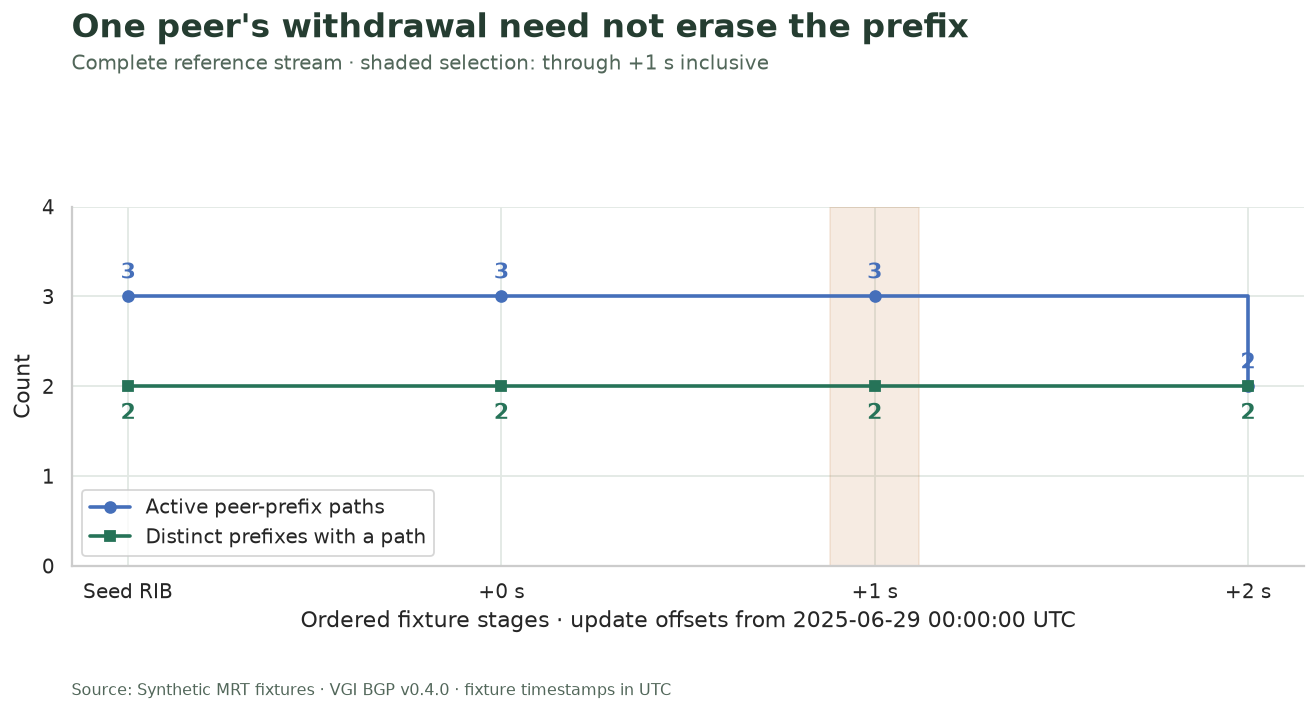

Through **+1 seconds**, the reconstructed view contains **3 active peer-prefix paths** covering **2 distinct prefixes**. A count of prefixes deliberately collapses multiple peer observations; retain the peer key when studying individual paths.

In [15]:
timeline = globals()["timeline"]
fig, ax = plt.subplots(figsize=(10.5, 5.5))
for column, label, color, marker in (
    ("active_paths", "Active peer-prefix paths", "#456fba", "o"),
    ("visible_prefixes", "Distinct prefixes with a path", "#267358", "s"),
):
    ax.plot(
        timeline.asof_second,
        timeline[column],
        color=color,
        marker=marker,
        label=label,
        linewidth=2,
        drawstyle="steps-post",
    )
    for row in timeline.itertuples():
        ax.annotate(
            str(int(getattr(row, column))),
            (row.asof_second, getattr(row, column)),
            xytext=(0, 10 if column == "active_paths" else -18),
            textcoords="offset points",
            ha="center",
            color=color,
            weight="bold",
        )
ax.axvspan(
    UPDATES_THROUGH_SECOND - 0.12,
    UPDATES_THROUGH_SECOND + 0.12,
    color="#c57b40",
    alpha=0.15,
)
ax.set(
    xticks=[-1, 0, 1, 2],
    xticklabels=["Seed RIB", "+0 s", "+1 s", "+2 s"],
    xlabel="Ordered fixture stages · update offsets from 2025-06-29 00:00:00 UTC",
    ylabel="Count",
    ylim=(0, max(timeline.active_paths.max(), timeline.visible_prefixes.max()) + 1),
)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(loc="lower left", frameon=True)
finish(
    fig,
    "One peer's withdrawal need not erase the prefix",
    f"Complete reference stream · shaded selection: through +{UPDATES_THROUGH_SECOND} s inclusive",
    f"state-through-{UPDATES_THROUGH_SECOND}.png",
)
chosen = timeline[timeline.asof_second == UPDATES_THROUGH_SECOND].iloc[0]
prose(
    f"Through **+{UPDATES_THROUGH_SECOND} seconds**, the reconstructed view contains **{int(chosen.active_paths)} active peer-prefix paths** covering **{int(chosen.visible_prefixes)} distinct prefixes**. A count of prefixes deliberately collapses multiple peer observations; retain the peer key when studying individual paths."
)

## Compare the selected state with its seed

The full join retains a path even when one side is absent. A withdrawn path has
**no current hop count**, rather than zero hops. We show the original and selected
AS paths and measure adjacent prepends separately. A shorter AS path is a
structural observation; it does not prove lower latency or explain routing policy.

In [16]:
%%sql differences <<
WITH selected AS (
 SELECT * FROM latest_states WHERE asof_second = {{ UPDATES_THROUGH_SECOND }}
)
SELECT coalesce(r.peer_ip, s.peer_ip) AS peer_ip,
       coalesce(r.peer_asn, s.peer_asn) AS peer_asn,
       coalesce(r.prefix, s.prefix) AS prefix,
       r.as_path AS seed_path, s.as_path AS selected_path,
       bgp.main.path_length(r.as_path) AS seed_hops,
       CASE WHEN s.event_type <> 'withdraw' THEN bgp.main.path_length(s.as_path) END AS selected_hops,
       bgp.main.as_path_prepends(r.as_path) AS seed_prepends,
       CASE WHEN s.event_type <> 'withdraw' THEN bgp.main.as_path_prepends(s.as_path) END AS selected_prepends,
       CASE WHEN s.event_type = 'withdraw' THEN 'Withdrawn'
            WHEN r.peer_ip IS NULL THEN 'New'
            WHEN r.as_path IS DISTINCT FROM s.as_path THEN 'Changed'
            ELSE 'Unchanged' END AS status
FROM rib r FULL OUTER JOIN selected s USING (peer_ip, peer_asn, prefix)
ORDER BY prefix, peer_ip;

,peer_ip,peer_asn,prefix,seed_path,selected_path,seed_hops,selected_hops,seed_prepends,selected_prepends,status
0,2001:db8::1,65001,2001:db8:abcd::/48,"[65001, 64500, 64600]","[65001, 64600]",3,2,0,0,Changed
1,192.0.2.1,65001,203.0.113.0/24,"[65001, 64500, 64500, 64512]","[65001, 64500, 64512]",4,3,1,0,Changed
2,198.51.100.7,65002,203.0.113.0/24,"[65002, 64513, 64512]","[65002, 64513, 64512]",3,3,0,0,Unchanged


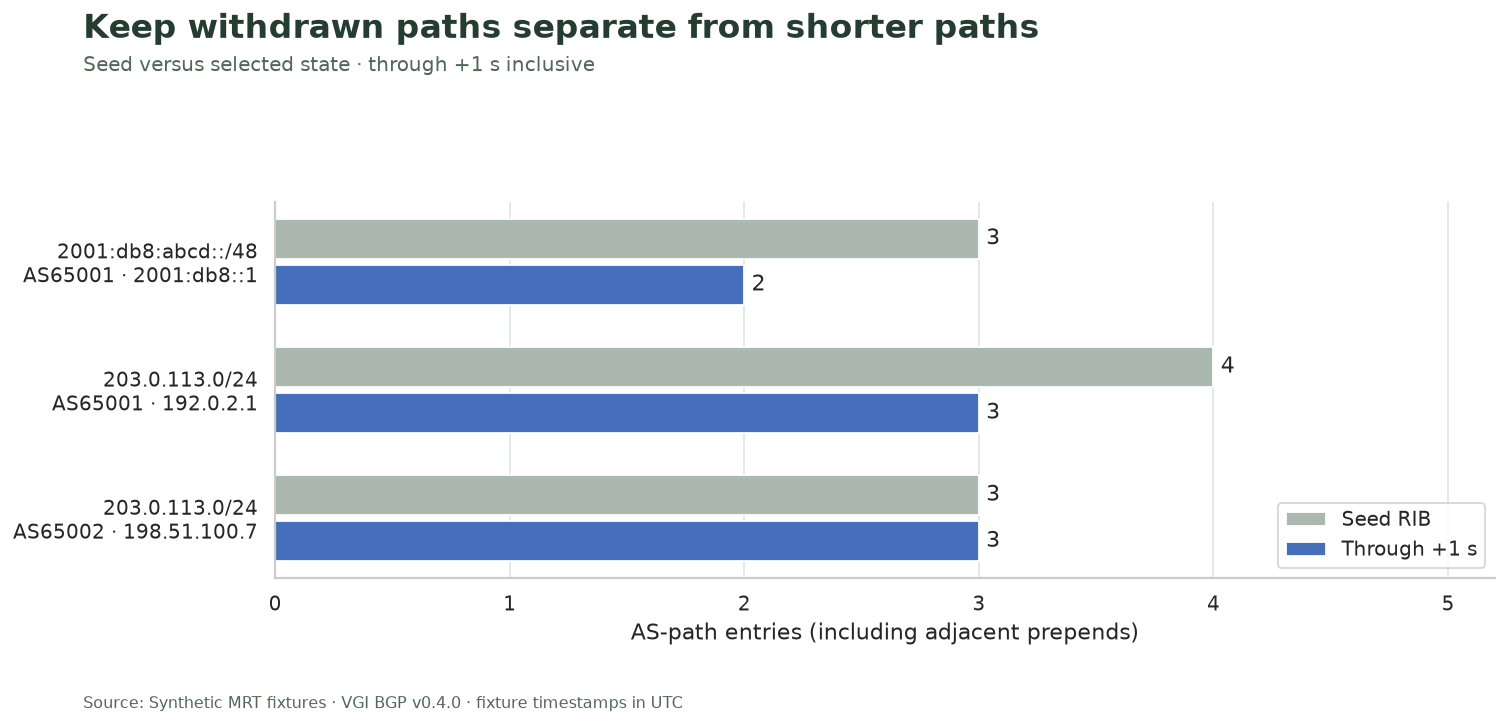

At this cutoff, **2 path(s) have changed** and **0 path(s) are withdrawn** relative to the seed. The table preserves the individual ASN lists and prepend counts, so a changed length can be interpreted without treating a withdrawal as a zero-length route.

In [17]:
differences = globals()["differences"]
display(differences)
y = np.arange(len(differences))
fig, ax = plt.subplots(figsize=(12, 5.6))
for offset, column, label, color in (
    (-0.18, "seed_hops", "Seed RIB", "#aab8b0"),
    (0.18, "selected_hops", f"Through +{UPDATES_THROUGH_SECOND} s", "#456fba"),
):
    present = differences[column].notna().to_numpy()
    values = differences.loc[present, column].to_numpy(dtype=float)
    bars = ax.barh(y[present] + offset, values, height=0.31, color=color, label=label)
    ax.bar_label(bars, fmt="%.0f", padding=4)
    for index in y[~present]:
        ax.text(
            0.08,
            index + offset,
            "withdrawn — no active path"
            if column == "selected_hops"
            else "no seed path",
            va="center",
            color="#a85337",
            fontsize=10,
        )
labels = [f"{r.prefix}\nAS{r.peer_asn} · {r.peer_ip}" for r in differences.itertuples()]
ax.set(
    yticks=y,
    yticklabels=labels,
    xlabel="AS-path entries (including adjacent prepends)",
    ylabel="",
)
ax.invert_yaxis()
ax.set_xlim(0, float(differences[["seed_hops", "selected_hops"]].max().max()) + 1.2)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=True)
finish(
    fig,
    "Keep withdrawn paths separate from shorter paths",
    f"Seed versus selected state · through +{UPDATES_THROUGH_SECOND} s inclusive",
    f"paths-through-{UPDATES_THROUGH_SECOND}.png",
)
changed = int((differences.status == "Changed").sum())
withdrawn = int((differences.status == "Withdrawn").sum())
prose(
    f"At this cutoff, **{changed} path(s) have changed** and **{withdrawn} path(s) are withdrawn** relative to the seed. The table preserves the individual ASN lists and prepend counts, so a changed length can be interpreted without treating a withdrawal as a zero-length route."
)

## Experiment: include the withdrawal

Change only **`UPDATES_THROUGH_SECOND = 2`**, restart and run all. Predict how the
active-path count and selected path bars will change, then compare them with the
number of distinct prefixes. The full timeline, input-quality report and seed
must stay fixed. Reset to **1**.

This small sequence demonstrates peer-specific state and explicit ordering. For
real archives, add collector/session identity, stable record ordering, reset
handling and input completeness checks before drawing conclusions about routing
changes. Origin authorization and data-plane reachability require other evidence.

In [18]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)